# Can we predict which route-hours will have bus delays? (Toronto TTC, 2022)

**Question:** given the hour, the calendar, the weather, the route and recent delays, how many delays should a route expect per scheduled trip?
**Data:** `data/toronto/route_hour.parquet`, built by `toronto_eda.ipynb` (one row per route × hour with scheduled service, Jan–Jun 2022).
**Design:** [docs/route-hour-model-design.md](docs/route-hour-model-design.md). Train on 1 Jan – 30 Apr, test on 1 May – 30 Jun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_poisson_deviance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ACCENT, MUTED = "#1f6feb", "#9aa4b2"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "grid.color": "#e5e7eb", "grid.linewidth": 0.8,
    "axes.grid.axis": "y", "legend.frameon": False,
})

## Load and split by time

In [2]:
rh = pd.read_parquet("data/toronto/route_hour.parquet")
CUT = pd.Timestamp("2022-05-01", tz="America/Toronto")
CATS = ["hour", "weekday", "day_type", "uoft_phase", "school", "group"]
FLAGS = ["holiday", "uoft_online", "omicron"]
NUMS = ["trips", "temp_c", "precip_mm", "rain_mm", "snowfall_cm", "snow_depth_m", "wind_kmh", "wind_gust_kmh",
        "visibility_m", "length_km", "n_stops", "lag1", "lag3", "city_lag1"]

X = pd.concat([pd.get_dummies(rh[CATS].astype(str), dtype=int), rh[FLAGS].astype(int), rh[NUMS]], axis=1)
is_train = rh.ts < CUT
train, test = rh[is_train], rh[~is_train]
X_train, X_test = X[is_train], X[~is_train]
print(f"train {len(train):,} route-hours ({train.n_delays.sum():,} delays), test {len(test):,} ({test.n_delays.sum():,} delays); {X.shape[1]} features")

train 454,837 route-hours (16,413 delays), test 231,561 (8,499 delays); 62 features


In [3]:
assert train.ts.max() < pd.Timestamp("2022-05-01", tz="America/Toronto") <= test.ts.min()
leaky = {"Incident", "Min Delay", "Min Gap", "Direction", "Vehicle", "Location", "n_delays"}
assert not leaky & set(X_train.columns)

## Baseline: each route's own history

The model has to beat a simple lookup: the training-period rate for that route, hour and service type. Cells with few trips are shrunk toward the hour × service-type rate, and that toward the overall rate, using 50 trips of prior weight, so no prediction is zero.

In [4]:
def baseline_rate(fit, score, m=50):
    rate = pd.Series(fit.n_delays.sum() / fit.trips.sum(), index=score.index)
    for keys in (["hour", "day_type"], ["route", "hour", "day_type"]):
        cell = score[keys].join(fit.groupby(keys)[["n_delays", "trips"]].sum(), on=keys).fillna(0)
        rate = (cell.n_delays + m * rate) / (cell.trips + m)
    return rate.to_numpy()

preds = {"baseline": baseline_rate(train, test) * test.trips.to_numpy()}

## Poisson regression and gradient-boosted trees

Both models predict the delay **rate per trip** (`n_delays / trips`), weighted by `trips`, so a route-hour with 20 trips counts 20 times as much as one with a single trip. Settings are tuned on time-ordered folds inside the training months: fit on everything before February, March and April in turn, score on that month, and average the Poisson deviance. The winning setting is refit on all of Jan–Apr.

In [5]:
def poisson(alpha):
    return make_pipeline(ColumnTransformer([("num", StandardScaler(), NUMS)], remainder="passthrough", verbose_feature_names_out=False),
                         PoissonRegressor(alpha=alpha, max_iter=1000))

def trees(leaves):
    return make_pipeline(HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05, max_leaf_nodes=leaves,
                                                       early_stopping=False, random_state=0))

def fit_rate(model, rows):
    w = train.trips[rows]
    return model.fit(X_train[rows], train.n_delays[rows] / w, **{f"{model.steps[-1][0]}__sample_weight": w})

def tune(make, settings):
    starts = [pd.Timestamp(f"2022-{m:02d}-01", tz="America/Toronto") for m in (2, 3, 4, 5)]
    cv = {}
    for s in settings:
        devs = []
        for start, end in zip(starts, starts[1:]):
            val = (train.ts >= start) & (train.ts < end)
            pred = fit_rate(make(s), train.ts < start).predict(X_train[val]) * train.trips[val]
            devs.append(mean_poisson_deviance(train.n_delays[val], pred))
        cv[s] = np.mean(devs)
    best = min(cv, key=cv.get)
    print(f"{make.__name__}: CV deviance " + ", ".join(f"{k}: {v:.4f}" for k, v in cv.items()) + f" -> picked {best}")
    return fit_rate(make(best), slice(None))

models = {"poisson": tune(poisson, [1e-4, 1e-2]), "trees": tune(trees, [15, 63])}
preds |= {name: m.predict(X_test) * test.trips.to_numpy() for name, m in models.items()}

poisson: CV deviance 0.0001: 0.2093, 0.01: 0.2126 -> picked 0.0001


trees: CV deviance 15: 0.1959, 63: 0.1963 -> picked 15


## How do the models score on May–June?

In [6]:
def capture_top10(pred):
    top = np.argsort(-pred)[: len(pred) // 10]
    return test.n_delays.to_numpy()[top].sum() / test.n_delays.sum()

results = pd.DataFrame({name: {"deviance": mean_poisson_deviance(test.n_delays, p), "capture_top10": capture_top10(p)}
                        for name, p in preds.items()}).T
null = mean_poisson_deviance(test.n_delays, test.trips * train.n_delays.sum() / train.trips.sum())
print(f"for reference, one flat rate for every route-hour scores deviance {null:.4f}")
display(results.style.format({"deviance": "{:.4f}", "capture_top10": "{:.1%}"}))

for reference, one flat rate for every route-hour scores deviance 0.2347


,deviance,capture_top10
baseline,0.2177,38.1%
poisson,0.2226,33.7%
trees,0.2072,41.2%


In [7]:
assert list(results.index) == ["baseline", "poisson", "trees"] and list(results.columns) == ["deviance", "capture_top10"]
assert np.isfinite(results.values).all() and (results.capture_top10 <= 1).all()

## Does the best model rank route-hours by risk?

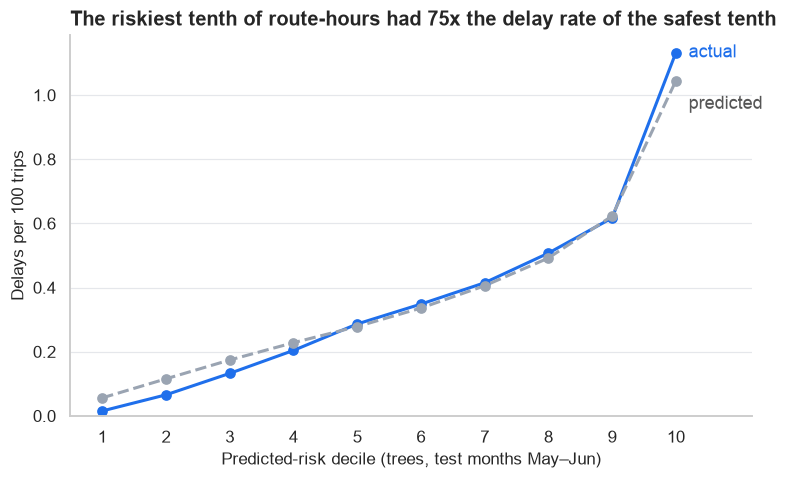

In [8]:
best = results.deviance.idxmin()
dec = pd.DataFrame({"actual": test.n_delays.to_numpy(), "pred": preds[best], "trips": test.trips.to_numpy()})
dec["decile"] = pd.qcut((dec.pred / dec.trips).rank(method="first"), 10, labels=range(1, 11))
d = dec.groupby("decile", observed=True)[["actual", "pred", "trips"]].sum()
d = 100 * d[["actual", "pred"]].div(d.trips, axis=0)

fig, ax = plt.subplots()
ax.plot(d.index.astype(int), d.actual, color=ACCENT, lw=2, marker="o")
ax.plot(d.index.astype(int), d.pred, color=MUTED, lw=2, marker="o", ls="--")
ax.annotate("actual", xy=(10, d.actual.iloc[-1]), xytext=(10.2, d.actual.iloc[-1]), color=ACCENT, va="center")
ax.annotate("predicted", xy=(10, d.pred.iloc[-1]), xytext=(10.2, d.pred.iloc[-1] * 0.93), color="#555", va="center")
ax.set(title=f"The riskiest tenth of route-hours had {d.actual.iloc[-1] / d.actual.iloc[0]:.0f}x the delay rate of the safest tenth",
       xlabel=f"Predicted-risk decile ({best}, test months May–Jun)", ylabel="Delays per 100 trips", xticks=range(1, 11), ylim=(0, None), xlim=(0.5, 11.2))
plt.show()

Predicted and actual rates rise together across the deciles, so the ranking is useful even though any single route-hour is still mostly luck.

## Which factors move the rate? (Poisson regression)

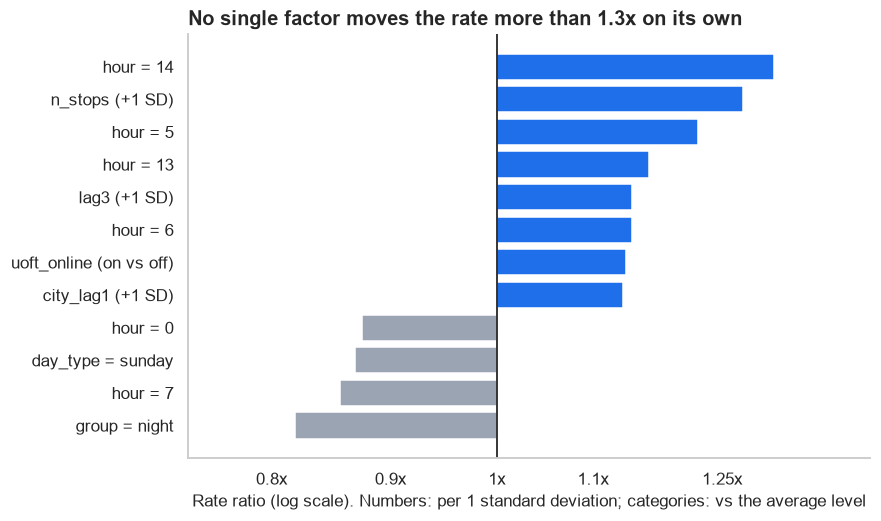

In [9]:
pois = models["poisson"]
coef = pd.Series(pois[-1].coef_, index=pois[0].get_feature_names_out())
top = coef.reindex(coef.abs().nlargest(12).index).sort_values()
cat_of = lambda f: next((c for c in CATS if f.startswith(c + "_")), None)
label = lambda f: f"{f} (+1 SD)" if f in NUMS else f"{f} (on vs off)" if f in FLAGS else f"{cat_of(f)} = {f[len(cat_of(f)) + 1:]}" if cat_of(f) else f
ratio = np.exp(top)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([label(f) for f in top.index], ratio - 1, left=1, color=[ACCENT if r > 1 else MUTED for r in ratio])
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.minorticks_off()
ticks = [t for t in [0.5, 0.67, 0.8, 0.9, 1, 1.1, 1.25, 1.5, 2] if ratio.min() * 0.9 <= t <= ratio.max() * 1.1]
ax.set_xticks(ticks, labels=[f"{t:g}x" for t in ticks])
ax.set_xlim(ratio.min() * 0.9, ratio.max() * 1.1)
ax.grid(False)
ax.set(title=f"No single factor moves the rate more than {max(ratio.max(), 1 / ratio.min()):.1f}x on its own",
       xlabel="Rate ratio (log scale). Numbers: per 1 standard deviation; categories: vs the average level")
plt.show()

Each effect is modest once the others are held fixed. `uoft_online` mostly overlaps the Omicron January, so it shouldn't be read as a university effect. Snow isn't in the top 12, and the test months had none.

## Findings

- **The trees beat the baseline.** On May–June, gradient-boosted trees score a Poisson deviance of **0.2072**, against **0.2177** for each route's own history and 0.2347 for one flat rate. Their riskiest 10% of route-hours hold **41%** of all delays; the baseline's hold 38%.
- **The Poisson regression does not beat the baseline** (0.2226, 34%). It sees only route *traits*, not each route's own history, and its effects can only add up. The trees can combine hour, route and recent delays.
- **The ranking is useful.** The top predicted decile had about 75x the delay rate of the bottom decile, and predicted rates track actual ones; the safest deciles are slightly over-predicted.
- **Effects are modest one at a time** (each within about 1.3x): early afternoons, routes with many stops and recent delays (same route and city-wide) raise the rate; Sundays, night routes, midnight and 7 am lower it.
- **Delays remain mostly luck at this grain:** even the best model cuts deviance only about 12% below a flat rate.

**Carrying this to AC Transit**
- The pipeline transfers: a route × hour table, scheduled GTFS trips as exposure, hourly Open-Meteo weather (request it in UTC; its local-time option ignores daylight saving), a UC Berkeley and holiday calendar, and lag features from the collector's own history.
- Start with the trees for prediction, and keep the Poisson model for explaining effects.
- AC Transit gives measured lateness, not logged incidents, so "delay" needs a threshold (for example, more than 5 minutes late) before results compare.
- Next steps: give the Poisson model each route's training-period rate, and add Berkeley events once the simple features are measured.